# Rice image classification (PyTorch CNN)

## 1. Setup

In [ ]:
#!pip install -q kagglehub scikit-learn

In [ ]:
import os, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 2. Download and find the data

In [ ]:
path = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")
BASE_DIR = os.path.join(path, "Rice_Image_Dataset")
if not os.path.exists(BASE_DIR):
    BASE_DIR = path

class_names = sorted(d for d in os.listdir(BASE_DIR) if os.path.isdir(os.path.join(BASE_DIR, d)))
NUM_CLASSES = len(class_names)
print(class_names)

Using Colab cache for faster access to the 'rice-image-dataset' dataset.
['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


## 3. Split the files first: 80% train / 10% validation / 10% test

In [ ]:
file_paths, labels = [], []
for idx, name in enumerate(class_names):
    folder = os.path.join(BASE_DIR, name)
    for f in os.listdir(folder):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            file_paths.append(os.path.join(folder, f))
            labels.append(idx)
file_paths, labels = np.array(file_paths), np.array(labels)

train_p, rest_p, train_y, rest_y = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    rest_p, rest_y, test_size=0.5, stratify=rest_y, random_state=SEED)

print(len(train_p), len(val_p), len(test_p))

60000 7500 7500


## 4. Transforms, Dataset and DataLoaders

In [ ]:
MEAN, STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)

transform = T.Compose([
    T.Resize(IMG_SIZE),
    T.ToTensor(),                 # 0-255 -> 0-1, HWC -> CHW
    T.Normalize(MEAN, STD),       # (x - 0.5) / 0.5 -> [-1, 1]
])

class RiceDataset(Dataset):
    def __init__(self, paths, ys, transform):
        self.paths, self.ys, self.transform = paths, ys, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), int(self.ys[i])

g = torch.Generator().manual_seed(SEED)
loader_kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=(device.type == "cuda"))

train_loader = DataLoader(RiceDataset(train_p, train_y, transform), shuffle=True,  generator=g, **loader_kw)
val_loader   = DataLoader(RiceDataset(val_p,   val_y,   transform), shuffle=False, **loader_kw)
test_loader  = DataLoader(RiceDataset(test_p,  test_y,  transform), shuffle=False, **loader_kw)  # order stays fixed

# Check normalization
x, y = next(iter(train_loader))
print("batch:", x.shape, "| value range:", x.min().item(), "to", x.max().item())

In [ ]:
# Visualize 1 batch of images from the training data loader
batch_images, batch_labels = next(iter(train_loader))   # shape: (32, 3, H, W)

plt.figure(figsize=(16, 8))
plt.suptitle('Rice Images in 1 Batch', fontsize=18, fontweight='bold', color='#634b66')

for i in range(min(32, len(batch_images))):
    ax = plt.subplot(4, 8, i + 1)
    img = batch_images[i] * 0.5 + 0.5                   # undo Normalize: [-1, 1] -> [0, 1]
    img = torch.permute(img, (1, 2, 0)).clamp(0, 1)     # (C, H, W) -> (H, W, C)
    plt.imshow(img)

    label = class_names[int(batch_labels[i])]
    plt.title(label, color='#634b66')
    plt.axis('off')
plt.show()

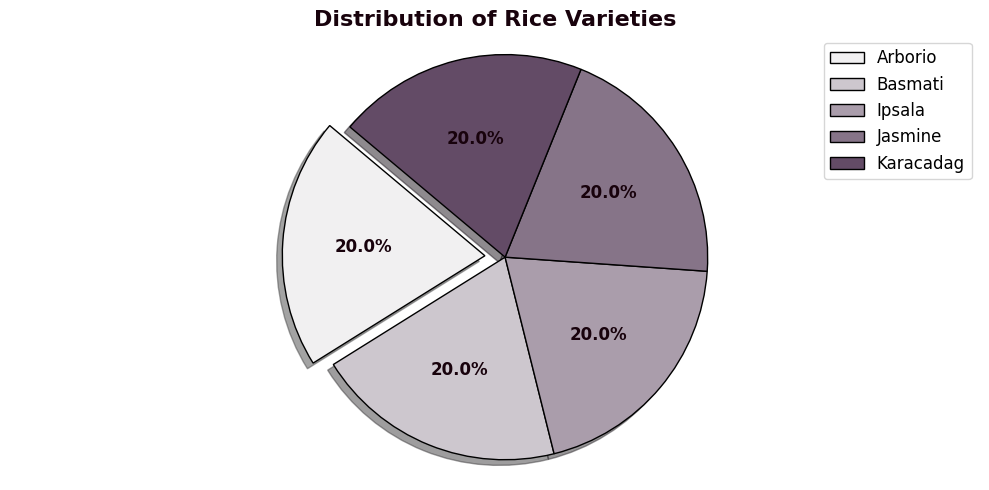

In [ ]:
import pandas as pd
import seaborn as sns

df = pd.DataFrame({
    "path": file_paths,
    "label": [class_names[i] for i in labels],
})

def label_counter(dataframe):
    """Plot a pie chart to show the distribution of rice varieties in the dataset."""
    fig, ax = plt.subplots(figsize=(10, 5))

    counts = dataframe['label'].value_counts()
    labels_, sizes = counts.index, counts.values

    colors = sns.light_palette("#634b66", n_colors=len(labels_), as_cmap=False)

    wedges, texts, autotexts = ax.pie(
        sizes, colors=colors,
        autopct='%1.1f%%', startangle=140,
        explode=(0.1, *([0] * (len(labels_) - 1))),
        wedgeprops=dict(edgecolor='black'), shadow=True
    )

    ax.set_title('Distribution of Rice Varieties', fontsize=16, fontweight='bold', color='#18020c')
    ax.axis('equal')
    ax.legend(wedges, labels_, loc="best", fontsize=12)

    # Customize text properties for the labels
    for text in texts:
        text.set_fontsize(12)
        text.set_fontweight('bold')
        text.set_color('#18020c')

    # Customize the percentage text on the pie chart
    for autotext in autotexts:
        autotext.set_fontsize(12)
        autotext.set_fontweight('bold')
        autotext.set_color('#18020c')

    plt.tight_layout()
    plt.show()

# Call the function to display the rice variety distribution
label_counter(df)

## 5. Models

In [ ]:
# Size of the flattened vector: 128 channels x (H/8) x (W/8), after three 2x2 poolings
n_flat = 128 * (IMG_SIZE[0] // 8) * (IMG_SIZE[1] // 8)    # 32,768 for 128x128 images

CNN = nn.Sequential(
    # Block 1: 3 -> 32 channels, 128x128 -> 64x64
    nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),

    # Block 2: 32 -> 64 channels, 64x64 -> 32x32
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),

    # Block 3: 64 -> 128 channels, 32x32 -> 16x16
    nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),

    # Turn the 128 x 16 x 16 maps into one long vector
    nn.Flatten(),

    # Decide the variety
    nn.Dropout(0.5),
    nn.Linear(n_flat, 128), nn.ReLU(),
    nn.Linear(128, NUM_CLASSES),
).to(device)


for name, m in [("CNN ", CNN)]:
    print(name, "parameters:", sum(p.numel() for p in m.parameters()))


!pip install -q torchinfo
from torchinfo import summary

summary(CNN,  input_size=(1, 3, *IMG_SIZE),
        col_names=("output_size", "num_params"), depth=3)


In [ ]:
CNN1 = nn.Sequential(
    # Block 1: 3 -> 32 channels, 128x128 -> 64x64
    nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
    nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),

    # Block 2: 32 -> 64 channels, 64x64 -> 32x32
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),

    # Block 3: 64 -> 128 channels, 32x32 -> 16x16
    nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
    nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),

    # Summarize each of the 128 maps into one number
    nn.AdaptiveAvgPool2d(1), nn.Flatten(),

    # Decide the variety
    nn.Dropout(0.5),
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, NUM_CLASSES),
).to(device)

for name, m in [("CNN1 ", CNN1)]:
    print(name, "parameters:", sum(p.numel() for p in m.parameters()))

!pip install -q torchinfo
from torchinfo import summary

summary(CNN1, input_size=(1, 3, *IMG_SIZE),
        col_names=("output_size", "num_params"), depth=3)

## 6. Training (each model saves its own best weights)

In [35]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            out = model(xb)
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n

def fit(model, ckpt_name, epochs=5, patience=2, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    best_val, bad = float("inf"), 0
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, optimizer)
        vl, va = run_epoch(model, val_loader)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        print(f"epoch {ep}/{epochs} | loss {tl:.4f} acc {ta:.4f} | val_loss {vl:.4f} val_acc {va:.4f}")
        if vl < best_val:
            best_val, bad = vl, 0
            torch.save(model.state_dict(), ckpt_name)
            print("  saved best ->", ckpt_name)
        else:
            bad += 1
            if bad >= patience:
                print("  early stopping")
                break
    model.load_state_dict(torch.load(ckpt_name, map_location=device))   # restore best weights
    return hist

history_cnn  = fit(CNN,  "best_cnn_flatten.pt")
history_cnn1 = fit(CNN1, "best_cnn_gap.pt")

epoch 1/5 | loss 0.1035 acc 0.9627 | val_loss 0.0169 val_acc 0.9943
  saved best -> best_cnn_flatten.pt
epoch 2/5 | loss 0.0282 acc 0.9906 | val_loss 0.0171 val_acc 0.9943
epoch 3/5 | loss 0.0216 acc 0.9932 | val_loss 0.0156 val_acc 0.9948
  saved best -> best_cnn_flatten.pt
epoch 4/5 | loss 0.0207 acc 0.9941 | val_loss 0.0092 val_acc 0.9971
  saved best -> best_cnn_flatten.pt
epoch 5/5 | loss 0.0185 acc 0.9947 | val_loss 0.0157 val_acc 0.9961
epoch 1/5 | loss 0.5930 acc 0.7343 | val_loss 0.1710 val_acc 0.9359
  saved best -> best_cnn_gap.pt
epoch 2/5 | loss 0.1148 acc 0.9623 | val_loss 0.0490 val_acc 0.9831
  saved best -> best_cnn_gap.pt
epoch 3/5 | loss 0.0797 acc 0.9750 | val_loss 0.0314 val_acc 0.9899
  saved best -> best_cnn_gap.pt
epoch 4/5 | loss 0.0413 acc 0.9874 | val_loss 0.0205 val_acc 0.9931
  saved best -> best_cnn_gap.pt
epoch 5/5 | loss 0.0385 acc 0.9882 | val_loss 0.0376 val_acc 0.9855


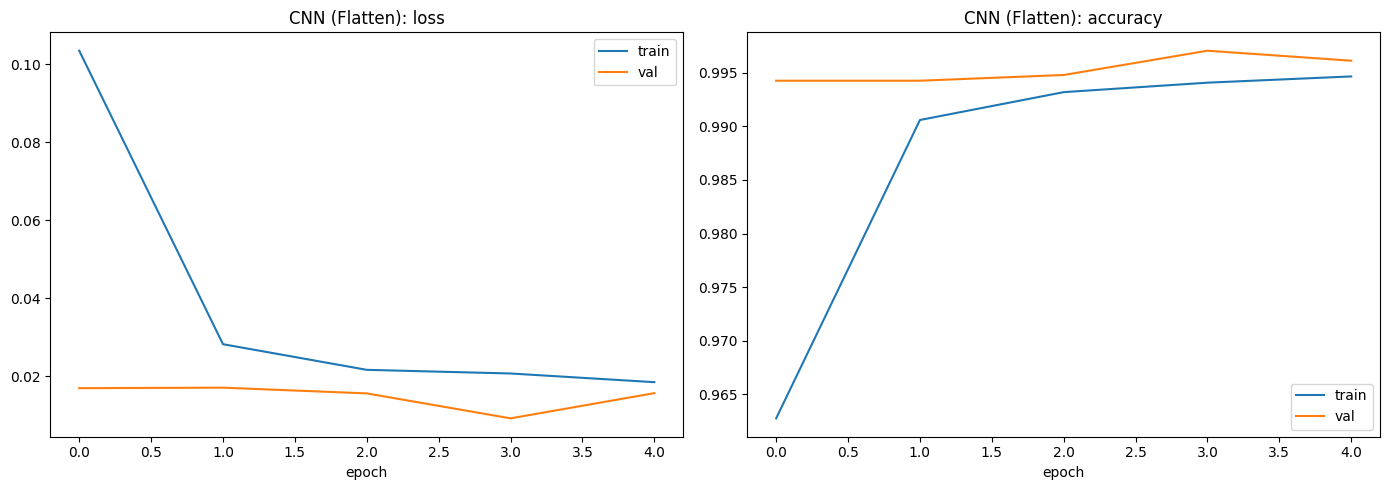

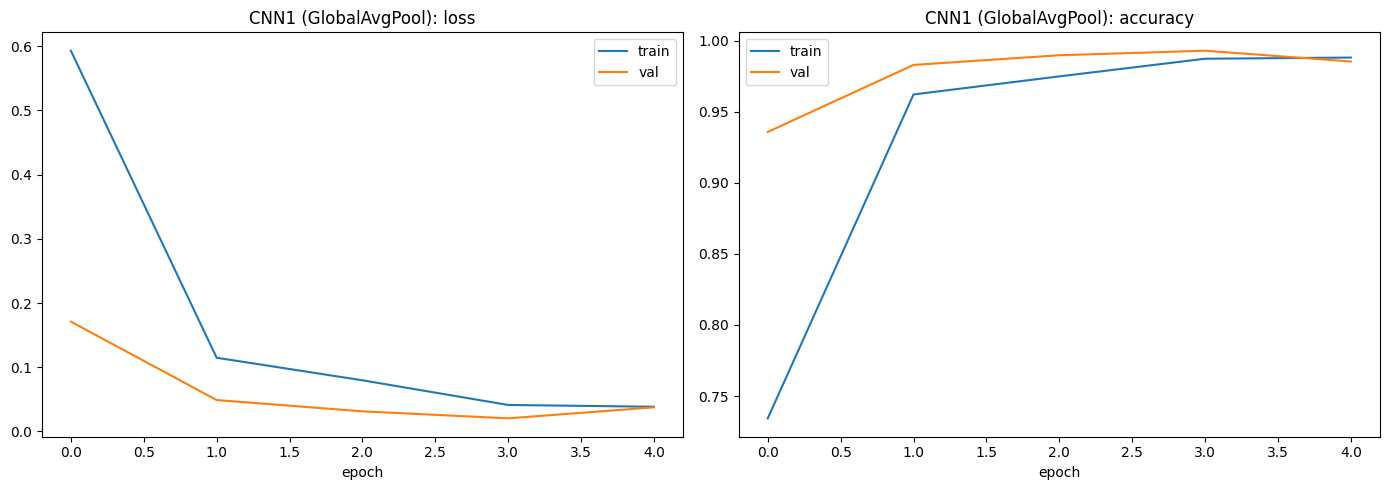

In [36]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
    ax[1].set_title(f"{title}: accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history_cnn,  "CNN (Flatten)")
plot_history(history_cnn1, "CNN1 (GlobalAvgPool)")

## 7. Compare models on the held-out test set

In [37]:
for name, m in [("CNN (Flatten)", CNN), ("CNN1 (GAP)", CNN1)]:
    loss, acc = run_epoch(m, test_loader)
    print(f"{name:15s} test loss {loss:.4f} | test accuracy {acc:.4f}")

CNN (Flatten)   test loss 0.0076 | test accuracy 0.9976
CNN1 (GAP)      test loss 0.0190 | test accuracy 0.9955


              precision    recall  f1-score   support

     Arborio     1.0000    0.9947    0.9973      1500
     Basmati     0.9940    0.9980    0.9960      1500
      Ipsala     1.0000    1.0000    1.0000      1500
     Jasmine     0.9953    0.9940    0.9947      1500
   Karacadag     0.9973    1.0000    0.9987      1500

    accuracy                         0.9973      7500
   macro avg     0.9973    0.9973    0.9973      7500
weighted avg     0.9973    0.9973    0.9973      7500



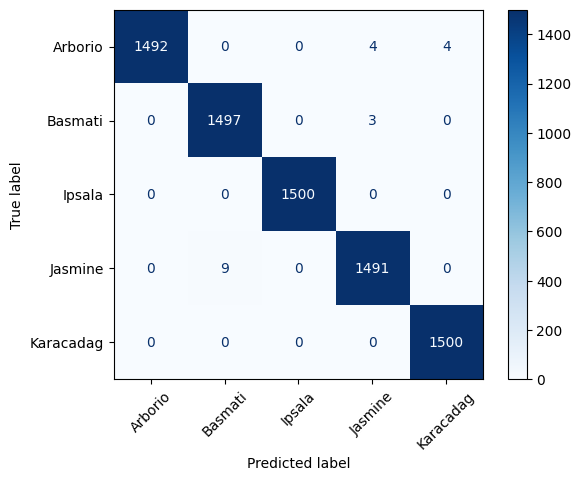

In [ ]:
final_model = CNN

@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    probs = []
    for xb, _ in loader:
        probs.append(torch.softmax(model(xb.to(device)), dim=1).cpu())
    return torch.cat(probs).numpy()

probs = predict_loader(final_model, test_loader)
y_pred, y_true = probs.argmax(axis=1), test_y

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    xticks_rotation=45, cmap="Blues")
plt.show()

## 8. Predictions on real images

In [ ]:
@torch.no_grad()
def predict_image(img_path, model=final_model):
    model.eval()
    img = Image.open(img_path).convert("RGB")
    xb = transform(img).unsqueeze(0).to(device)          # same transform as training
    p = torch.softmax(model(xb), dim=1)[0].cpu()
    return class_names[int(p.argmax())], float(p.max())

label, conf = predict_image(test_p[0])
print(f"true: {class_names[test_y[0]]} | predicted: {label} ({conf:.1%})")

true: Ipsala | predicted: Ipsala (100.0%)


In [40]:
def denorm(img):   # undo Normalize for display: [-1, 1] -> [0, 1], (C,H,W) -> (H,W,C)
    return (img * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

# 9 random test images, predicted in one batch
idx = np.random.default_rng(SEED).choice(len(test_p), 9, replace=False)
...

Ellipsis

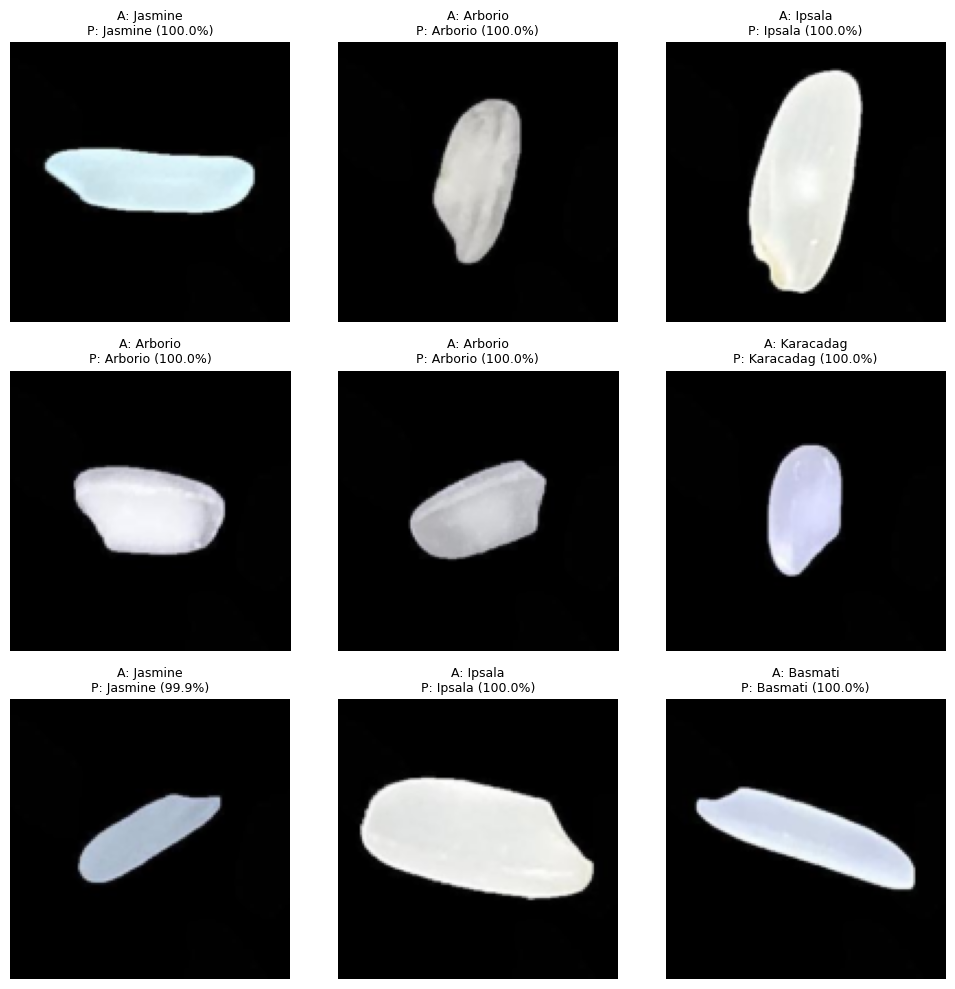

In [41]:
# 9 random test images, predicted in one batch
idx = np.random.default_rng(SEED).choice(len(test_p), 9, replace=False)
batch = torch.stack([transform(Image.open(test_p[i]).convert("RGB")) for i in idx])
with torch.no_grad():
    final_model.eval()
    p9 = torch.softmax(final_model(batch.to(device)), dim=1).cpu()

plt.figure(figsize=(10, 10))
for k, i in enumerate(idx):
    plt.subplot(3, 3, k + 1)
    plt.imshow(denorm(batch[k]))
    plt.title(f"A: {class_names[test_y[i]]}\nP: {class_names[int(p9[k].argmax())]} ({float(p9[k].max()):.1%})", fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()